In [1]:
#Import statements
from skimage import color, io, filters, morphology, measure, exposure, transform
import matplotlib.pyplot as plt
import numpy as np
import math
import scipy as sci
from scipy.optimize import fsolve
import pandas as pd
from os import listdir
import os
import re

In [2]:
# DEFINE DIRECTORY TO SAVE DATA
# DO NOT RERUN THIS CELL FOR THE SAME TRIAL: o/w will error, unless you delete "Processed_Data" folder

## Select which Trial to Run (folder must be within the direcFolder listed below)
run = str('20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)')                                 #CHANGE ACCORDING TO TRIAL

## Make Directory to Save Data depending on User
direcFolder = str('./Image Processing/')            #this folder should be within the same folder as this code file
directory = direcFolder + run                       #this folder should exist with the pre-lens and droplet images
os.makedirs(direcFolder + run + '/Processed_Data' ) #make "Processed_Data" directory folder for saving data

## Make Files to Save Data
# Curve Equations to .txt
curve_eqns_filepath = direcFolder + run + '/Processed_Data/curve_equations.txt'              #CREATE TXT FILE
curve_eqns = open(curve_eqns_filepath, 'w')                                     
curve_eqns.write('Filename,Cycle,x_offset,y_offset,a,b,RMSE')                                #SAVE INFO TO A TXT FILE
curve_eqns.close()

# CA Data to .csv
data_sum_filepath = direcFolder + run + '/Processed_Data/data.csv'                           #create csv file
data_sum = open(data_sum_filepath, 'w')                                          
data_sum.write('Filename,Cycle,Left CA,Right CA,Left Cut,Right Cut,NRMSE (for Ellipse)')     #SAVE INFO TO A CSV FILE
data_sum.close()

In [3]:
# SET OF FUNCTIONS

# Reads the images from the directory and sorts them numerically
def readImages(directory):
    fname_list = [f'/{fname}' for fname in listdir(directory) if '.jpg' in fname]
    
    droplet_pic = sorted([f for f in fname_list if "/Image_" in f],
        key=lambda x: tuple(map(int, re.findall(r'\d+', x)))) # a '\d' means digit, adding + means one or more digits, to sort 10s properly
    
    lens_pic = sorted([f for f in fname_list if "/preLens_" in f or "/pre_lens" in f],
        key=lambda x: tuple(map(int, re.findall(r'\d+', x)))) #creates tuples, i.e., cycle1_run2 --> (1,2)
    
    return droplet_pic, lens_pic

# Selects the images to process based on "selection" in main()
def selectImages(selection, droplet_pic, lens_pic, experiment):
    if experiment == "B&R":
        if selection[0] == "all":    
            droplet_pic = droplet_pic[0:]
            lens_pic = lens_pic[0:]
        else:
            #Create null lists to store desired droplet and lens pics
            dropletPic = []
            lensPic = []
            selection_pairs = set() #creates empty set

            def parse_name(fname):
                capture = re.search(r'run(\d+)_(?:cycle|drop)(\d+)', fname) #captures the numbers after run and after cycle/drop
                return tuple(map(int, capture.groups())) if capture else None
            
            #Collects the different run numbers from all droplet images
            all_run_nums = {parse_name(f)[0] for f in droplet_pic}
            
            if len(all_run_nums) == 1:                    #if only one run/cycle
                onlyRun_num = next(iter(all_run_nums))    #run value of the singular run
                for cycle in selection:
                    selection_pairs.add((onlyRun_num, cycle))
            else:                                         #if more than 1 run/cycle
                for s in selection:
                    selection_pairs.add(parse_name(s))

            dropletPic = [f for f in droplet_pic if parse_name(f) in selection_pairs]
            lensPic = [f for f in lens_pic if parse_name(f) in selection_pairs]
            
            droplet_pic = sorted(dropletPic, key=parse_name)
            lens_pic = sorted(lensPic, key=parse_name)
            
    elif experiment == "T&RH":
        if selection[0] == "all":    
            droplet_pic = droplet_pic[0:]
            lens_pic = lens_pic[0:]
        else:
            #Create null lists to store desired droplet and lens pics
            dropletPic = []
            lensPic = []

            for j in selection:
                dropletPic = dropletPic + droplet_pic[j:j+1]
                lensPic = lensPic + lens_pic[j:j+1]

            droplet_pic = sorted(dropletPic)
            lens_pic = sorted(lensPic)
            
    print(droplet_pic)
    print(lens_pic)
    return droplet_pic, lens_pic

def test_droplet_img(directory, droplet_pic, img_crop_values):
    droplet_img = droplet_pic[0]
    img = io.imread(directory + droplet_img, as_gray=True)
    y1 = img_crop_values[0]
    y2 = img_crop_values[1]
    x1 = img_crop_values[2]
    x2 = img_crop_values[3]
    img_crop = img[y1:y2,x1:x2] #img_crop = img[300:1200,205:1405]
    
    print('Test Crop:', droplet_img.lstrip('/'))
    fig, ax = plt.subplots()    #CREATE PLOT
    ax.imshow(img_crop, cmap='Greys_r')

    return y1,y2,x1,x2


### FUNCTIONS FOR CA CACLULATIONS

# Equations
def ellipse_equation(x, x_offset, y_offset, a, b):         #for Ellipse and Tangent
    val = (1 - (((x-x_offset)**2)/(a**2))) * (b**2)
    val = np.clip(val, 0, None)
    return np.sqrt(val) + y_offset

def ellipse_F(x, y, x0, y0, a, b):                         #for Ellipse
    return ((x - x0)**2)/a**2 + ((y - y0)**2)/b**2 - 1

def ellipse_grad(x, y, x0, y0, a, b):                      #for Ellipse
    Fx = 2*(x - x0)/a**2
    Fy = 2*(y - y0)/b**2
    return np.array([Fx, Fy])

def ellipse_distance(x, y, params):                        #for Ellipse
    x0, y0, a, b = params

    F = ellipse_F(x, y, x0, y0, a, b)

    grad = ellipse_grad(x, y, x0, y0, a, b)
    grad_norm = np.linalg.norm(grad, axis=0)

    return np.abs(F) / grad_norm

def ellipse_tangent_dir(x, y, x0, y0, a, b):               #for Ellipse
    Fx, Fy = ellipse_grad(x, y, x0, y0, a, b)
    t = np.array([-Fy, Fx]) #perpendicular
    return t / np.linalg.norm(t)

def intersection_eq(p, e1, e2):                            #for Ellipse
    x, y = p
    return [
        ellipse_F(x, y, *e1),
        ellipse_F(x, y, *e2)
    ]

def intersection_angle(x, y, e1, e2):                      #for Ellipse
    g1 = ellipse_grad(x, y, *e1)
    g2 = ellipse_grad(x, y, *e2)

    cos_theta = np.dot(g1, g2) / (
        np.linalg.norm(g1) * np.linalg.norm(g2)
    )

    theta = np.arccos(np.clip(cos_theta, -1, 1))
    
    return theta

def line_equation(x, m, b):                                #for Ellipse and Tangent
    return (m * x) + b

# Processing image & droplet (for both Ellipse and Tangent)
def processed_image(directory, fname, y1,y2,x1,x2):
    img = io.imread(directory + fname, as_gray=False)                       #LOAD IMAGE (in colour), img is NumPy array
    
    img_crop = img[y1:y2,x1:x2]                                             #CROP IMAGE: [y axis range, x axis range], may need to tune

    img_gray = color.rgb2gray(img_crop)                                     #GREYSCALE IMAGE

    img_blur = filters.gaussian(img_gray, sigma=5, preserve_range=True)     #BLUR IMAGE

    img_gamma_correct = exposure.adjust_gamma(img_blur, gamma=5)            #INCREASE CONTRAST

    thr = filters.threshold_otsu(img_gamma_correct)                         #PROVIDES THRESHOLD THAT DETERMINES WHICH PIXELS ARE IN FOREGROUND
    img_thr = img_gamma_correct > thr

    contours = measure.find_contours(img_thr)
    idx_max = np.argmax([len(contour) for contour in contours])             #FIND THE LONGEST CONTOUR
    main_contour = contours[idx_max]
    main_contour_x = np.flip(main_contour[:,1])
    main_contour_y = np.flip(img_crop.shape[0] - main_contour[:,0])

    return img, img_crop, img_thr, main_contour, main_contour_x, main_contour_y

# Determining equation for contact lens curve (for both Ellipse and Tangent)
def lensCurve(img_thr, ellipse_equation, main_contour_x, main_contour_y):
    #Determine Lens Curve Parameters
    p0 = (img_thr.shape[1]//2, 0, img_thr.shape[1]/2, img_thr.shape[0]/4) #initial guess
    bounds = ([0, -img_thr.shape[0], 3, 1], [img_thr.shape[1], img_thr.shape[0], img_thr.shape[1], img_thr.shape[0]*7/4])
    
    params, _ = sci.optimize.curve_fit(ellipse_equation, main_contour_x, main_contour_y, p0=p0, bounds=bounds)
    print(f'Parameters of lens curve equation - x_offset, y_offset, a, b: {params}')

    # Determine Lens Curve
    lens_curve_x = main_contour_x
    lens_curve_y = ellipse_equation(main_contour_x, *params)

    # Determine Root Mean Square Error (RMSE) of Lens Curve
    sum_squared = 0
    for point in range(len(lens_curve_x)):
        sum_squared += (lens_curve_y[point] - main_contour_y[point])**2
    RMSE = math.sqrt(sum_squared/len(lens_curve_x))
    RMSE = round(RMSE,2)    

    return lens_curve_x, lens_curve_y, params, RMSE
    
# Determining contours (for both Ellipse and Tangent)
def dropletContour(main_contour_x, main_contour_y, lens_curve_x, lens_curve_y, min_len): #min_len can be tuned
    mask_droplet = np.zeros(len(main_contour_x), dtype = bool) #initializes array for droplet contour
    
    for j in range(len(main_contour_x) - 40):                           #SEPARATE OUT THE DROPLET CONTOUR
        main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
        lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
        curve_diff = main_contour_y[j+10] - lens_curve_y[j+10]

        ## NOTE: May toggle between (comment/uncomment) the three different if statements to change the lens_curve_slope multiplier (smaller multiplier = less curved)
        if curve_diff > 5 and ((abs(main_contour_slope) > abs(1.5*lens_curve_slope)) or (abs(main_contour_slope) == math.inf)):     #if the main contour deviates enough from the lens curve
            mask_droplet[j+10] = True
        # if curve_diff > 5 and ((abs(main_contour_slope) > abs(1*lens_curve_slope)) or (abs(main_contour_slope) == math.inf)):     #if the main contour deviates enough from the lens curve
        #     mask_droplet[j+10] = True
        # if curve_diff > 5 and ((abs(main_contour_slope) > abs(0.7*lens_curve_slope)) or (abs(main_contour_slope) == math.inf)):     #if the main contour deviates enough from the lens curve
        #     mask_droplet[j+10] = True

    indices = np.where(mask_droplet)[0]
    splits = np.where(np.diff(indices) > 30)[0]   #np.diff() calculates the discerete differences along "indices": output[i] = indices[i+1] - indices[i]
    segments = np.split(indices, splits + 1)      #np.split(array, sections): splits array along the entries in sections

    segments = [seg for seg in segments if len(seg) >= min_len]

    largest_segment = np.concatenate(segments)

    droplet_contour_x = main_contour_x[largest_segment]
    droplet_contour_y = main_contour_y[largest_segment]

    droplet_contour_x = np.asarray(droplet_contour_x)
    droplet_contour_y = np.asarray(droplet_contour_y)

    return droplet_contour_x, droplet_contour_y

# Makes initial guess for Ellipse method
def ellipseInitialGuess(droplet_contour_x, droplet_contour_y):
    p0_1 = (droplet_contour_x[0] + droplet_contour_x[-1])/ 2
    p0_3 = (max(droplet_contour_x)-droplet_contour_x[0])/2
    p0_4 = (max(droplet_contour_y)-droplet_contour_y[0])/4
    
    p0_drop = (p0_1, droplet_contour_y[0], p0_3, p0_4)                  #SET THE INITIAL GUESS FOR THE PARAMETERS FOR DROPLET CURVE
    
    return p0_drop

# Calculated intersections for Ellipse method
def ellipseIntersections(droplet_contour_x, droplet_contour_y, p0_drop, img, params):
    p0 = p0_drop
    bounds = ([0, -img.shape[0], 0.5, 0.5], [img.shape[1], img.shape[0], img.shape[1], img.shape[0]*7/4])
    
    params_drop, _ = sci.optimize.curve_fit(ellipse_equation, droplet_contour_x, droplet_contour_y, p0=p0, bounds=bounds)
    print('Parameters of droplet curve equation - x_offset, y_offset, a, b:', params_drop)
    
    x_0, y_0, a, b = params_drop

    droplet_curve_x_top = np.linspace(x_0 - a, x_0 + a, 1000)            #CREATE ELLIPSE AROUND DROPLET
    droplet_curve_x_bottom = np.linspace(x_0 + a, x_0 - a, 1000)
    
    droplet_curve_y_top = ellipse_equation(droplet_curve_x_top, *params_drop)
    droplet_curve_y_bottom = 2*params_drop[1] - droplet_curve_y_top

    droplet_curve_x = np.concatenate((droplet_curve_x_top, droplet_curve_x_bottom))
    droplet_curve_y = np.concatenate((droplet_curve_y_top, droplet_curve_y_bottom))

                                                                         #DETERMINE INTERSECTION POINTS BTWN ELLIPSES 
    guesses = [(x_0 - a, y_0),   #left CA guess
               (x_0 + a, y_0)]   #right CA guess
    solutions = []
    
    for p0 in guesses:                                                   #FIND INTERSECTIONS AND ANGLE BETWEEN CURVES
        x_int, y_int = fsolve(intersection_eq, p0, args=(params, params_drop))
        solutions.append((x_int, y_int))

    return params_drop, droplet_curve_x, droplet_curve_y, solutions

# Find NRMSE for Ellipse method
def findNRMSE(params_drop, solutions, droplet_contour_x, droplet_contour_y, droplet_curve_x):
    y_int_lower = np.min([solutions[0][1], solutions[1][1]])
    y_int_greater = np.max([solutions[0][1], solutions[1][1]])
    
    y_cut = y_int_greater + (0.25 * (np.max(droplet_contour_y) - y_int_greater))
    mask = droplet_contour_y <= y_cut
    
    x_test = droplet_contour_x[mask]
    y_test = droplet_contour_y[mask]
    
    d = ellipse_distance(x_test, y_test, params_drop)
    
    RMSE = np.sqrt(np.mean(d**2))
    
    footprint_radius = 0.5 * (droplet_curve_x.max() - droplet_curve_x.min())
    NRMSE = RMSE / footprint_radius

    return NRMSE

# Determine CA for Ellipse method
def ellipseCA(CA, solutions, params, params_drop):
    for x_int, y_int in solutions: 
        theta = intersection_angle(x_int, y_int, params, params_drop) 
        theta_deg = np.degrees(theta)
        CA.append(round(theta_deg, 2))

    return CA

# Determine tangent line points for Ellipse method
def ellipseTangentPoints(solutions, params, params_drop):
    L1x_list, L1y_list, L2x_list, L2y_list = [], [], [], []              #MAKE EMPTY LISTS
    
    for soln in range(len(solutions)):                                   #FIND TANGENT LINE POINTS
        x, y = solutions[soln]
        t1 = ellipse_tangent_dir(x, y, *params)
        t2 = ellipse_tangent_dir(x, y, *params_drop)

        s = np.linspace(-100, 100, 100)
        
        # Tangent line points
        L1x = x + s * t1[0]
        L1y = y + s * t1[1]
        
        L2x = x + s * t2[0]
        L2y = y + s * t2[1]

        L1x_list.append(L1x)
        L1y_list.append(L1y)
        L2x_list.append(L2x)
        L2y_list.append(L2y)

    return L1x_list, L1y_list, L2x_list, L2y_list

# Function to cut contour of droplet for Tangent method 
def cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y):
    #Redefine contour values to cropped contour values
    if right_cut > 1 :
        droplet_contour_x = droplet_contour_x[left_cut:-right_cut] 
        droplet_contour_y = droplet_contour_y[left_cut:-right_cut]
    else:
        droplet_contour_x = droplet_contour_x[left_cut:] 
        droplet_contour_y = droplet_contour_y[left_cut:]
        
    return droplet_contour_x, droplet_contour_y
    
## Calculated CAs given droplet contour (all for Tangent method)
# Calculate left CA (used in cut_leftCA)
def leftCA(droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y):
    #Determine right contact angle
    left_drop_vector = [droplet_contour_x[10] - droplet_contour_x[0],       #OBTAIN DROPLET VECTOR
                        droplet_contour_y[10] - droplet_contour_y[0]]         
    left_drop_slope = left_drop_vector[1]/left_drop_vector[0]
    left_drop_intercept = droplet_contour_y[0] - (left_drop_slope * droplet_contour_x[0])

    left_index = np.argwhere(lens_curve_x == droplet_contour_x[0])[0]
    left_lens_vector = [lens_curve_x[left_index[0] + 5] - lens_curve_x[left_index[0]- 5], 
                        lens_curve_y[left_index[0] + 5] - lens_curve_y[left_index[0]- 5]]
    left_lens_slope = left_lens_vector[1]/left_lens_vector[0]
    left_lens_intercept = lens_curve_y[left_index[0]] - (left_lens_slope * lens_curve_x[left_index[0]])

    #Calculate left CA
    left_CA = np.arccos(np.dot(left_lens_vector,
                               left_drop_vector) / (np.linalg.norm(left_lens_vector) * np.linalg.norm(left_drop_vector))) * 180/math.pi
    left_CA = round(left_CA,2)

    return left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA

# Calculate right CA (used in cut_rightCA)
def rightCA(droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y):
    right_drop_vector = [droplet_contour_x[-11] - droplet_contour_x[-1], 
                         droplet_contour_y[-11] - droplet_contour_y[-1]]    #OBTAIN DROPLET VECTOR
    right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
    right_drop_intercept = droplet_contour_y[-1] - (right_drop_slope * droplet_contour_x[-1])

    right_index = np.argwhere(lens_curve_x == droplet_contour_x[-1])[0]
    right_lens_vector = [lens_curve_x[right_index[0] - 5] - lens_curve_x[right_index[0] + 5], 
                         lens_curve_y[right_index[0] -5] - lens_curve_y[right_index[0] + 5]]
    right_lens_slope = right_lens_vector[1]/right_lens_vector[0]
    right_lens_intercept = lens_curve_y[right_index[0]] - (right_lens_slope * lens_curve_x[right_index[0]])

    #Calculate right CA
    right_CA = np.arccos(np.dot(right_lens_vector,
                                right_drop_vector) / (np.linalg.norm(right_lens_vector) * np.linalg.norm(right_drop_vector))) * 180/math.pi
    right_CA = round(right_CA,2)

    return right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA

## Automatic determination of final CAs based on auto-cutting droplet contour (for Tangent)
# Auto calculate left CA
def cut_leftCA(autoLeft, left_cut, interface_offset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y):
    #Get initial value for the following variables
    left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA = leftCA(droplet_contour_x, droplet_contour_y, 
                                                                                                 lens_curve_x, lens_curve_y)
    counter = 0 #b/c need to return this value

    #Manual Cutting Droplet Contour (cuts both sides)
    if autoLeft == False: 
        if left_cut != 0:
            droplet_contour_xLEFT, droplet_contour_yLEFT = cutFunc(left_cut, 0, droplet_contour_x, droplet_contour_y) #set right_cut to 0 since not doing that side
            left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA = leftCA(droplet_contour_xLEFT, 
                                                                                                         droplet_contour_yLEFT, 
                                                                                                         lens_curve_x, lens_curve_y)
            counter = left_cut #b/c counter in auto cut is the actual left_cut, so code is returning counter in left_cut position
    
    #Automatically cut droplet_contour based on Left Tangent
    else: 
        left_cut = 0
        right_cut = 0 #need this b/c cutFunc uses it
        toCut = False
        runCut = True 
        
        cut_index = np.argwhere(main_contour_x == droplet_contour_x[interface_offset])[0] #starting index of where to cut
        
        while runCut:
            for k in range(len(droplet_contour_x)):
                if k == 0: #otherwise, use the save_droplet_contour_y from previous run
                    save_droplet_contour_y = droplet_contour_y[interface_offset]
                    
                if left_drop_slope >= 0:
                    condition = save_droplet_contour_y > (line_equation(main_contour_x[cut_index], left_drop_slope, left_drop_intercept))
                elif left_drop_slope < 0: #or left_drop_slope == float('inf'):
                    condition = save_droplet_contour_y < (line_equation(main_contour_x[cut_index], left_drop_slope, left_drop_intercept))
                elif left_drop_slope == float('inf'):
                    conditions = droplet_contour_xLEFT[k + interface_offset] < main_contour_x[cut_index]
                    
                if condition:
                    toCut = True
                    left_cut = 1 #cut an additional 1 point, not += 1 b/c droplet_contour is already cut from previous run

                    #Cut left side and recalculate left CA
                    droplet_contour_x, droplet_contour_y = cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y)
                    left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA = leftCA(droplet_contour_x, 
                                                                                                                 droplet_contour_y, 
                                                                                                                 lens_curve_x, lens_curve_y)
    
                    cut_index = np.argwhere(main_contour_x == droplet_contour_x[k + interface_offset])[0] #recalculate where to cut
                    save_droplet_contour_y = droplet_contour_y[k + interface_offset]
                    counter += 1
                    
                else:
                    if counter == 0 and toCut == False:
                        print(f'NO LEFT CUT NEEDED')
                    print("LEFT SIDE:")
                    print('droplet contour y: ', save_droplet_contour_y, 'vs tangent line y : ', 
                          line_equation(main_contour_x[cut_index], left_drop_slope, left_drop_intercept)[0] )
                    print('droplet contour x: ', droplet_contour_x[k + interface_offset] , 
                          'vs tangent line x : ', main_contour_x[cut_index], '\n')
                    runCut = False
                    break
                    
    return droplet_contour_x, droplet_contour_y, left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA, counter #counter = how many points left side was cut (aka left_cut)

# Auto calculate right CA
def cut_rightCA(autoRight, right_cut, interface_offset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y):
    #Get initial value for the following variables
    right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA = rightCA(droplet_contour_x, 
                                                                                                       droplet_contour_y, 
                                                                                                       lens_curve_x, lens_curve_y)
    
    if autoRight == False: #Manual cutting Droplet Contour (cuts both sides)
        if right_cut != 0:
            droplet_contour_xRIGHT, droplet_contour_yRIGHT = cutFunc(0, right_cut, droplet_contour_x, droplet_contour_y) #set left_cut to 0 since not doing that side
            right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA = rightCA(droplet_contour_xRIGHT, 
                                                                                                               droplet_contour_yRIGHT, 
                                                                                                               lens_curve_x, lens_curve_y)
    else: #Automatically cut droplet_contour based on Right Tangent
        left_cut = 0 #need this b/c cutFunc uses it
        right_cut = 1
        toCut = False
        runCut = True
        
        cut_index = np.argwhere(main_contour_x == droplet_contour_x[-interface_offset])[0] #starting index of where to cut
        
        #Making new droplet and main contours to change for right side only
        droplet_contour_xRIGHT = droplet_contour_x
        droplet_contour_yRIGHT = droplet_contour_y
    
        counter = 0
        while runCut:
            for k in range(len(droplet_contour_x)):
                if k == 0: #otherwise, use the save_droplet_contour_y from previous run
                    save_droplet_contour_y = droplet_contour_y[-interface_offset]
    
                if right_drop_slope < 0:
                    condition = save_droplet_contour_y > (line_equation(main_contour_x[cut_index], right_drop_slope, right_drop_intercept))
                elif right_drop_slope >= 0: #or right_drop_slope == float('inf'):
                   condition = save_droplet_contour_y < (line_equation(main_contour_x[cut_index], right_drop_slope, right_drop_intercept))
                elif right_drop_slope == float('inf'):
                    conditions = droplet_contour_x[- (k + interface_offset)] > main_contour_x[cut_index]
                    
                if condition:
                    toCut = True
                    right_cut += 1
                    droplet_contour_xRIGHT, droplet_contour_yRIGHT = cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y)
                    
                    right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA = rightCA(droplet_contour_xRIGHT, 
                                                                                                                       droplet_contour_yRIGHT, 
                                                                                                                       lens_curve_x, lens_curve_y)
    
                    cut_index -= 1
                    save_droplet_contour_y = droplet_contour_y[-(k + interface_offset)]
                    counter += 1

                else:
                    if counter == 0 and toCut == False:
                        print(f'NO RIGHT CUT NEEDED')
                    print("RIGHT SIDE:")
                    print('droplet contour y: ', save_droplet_contour_y, 'vs tangent line y: ', 
                          line_equation(main_contour_x[cut_index], right_drop_slope, right_drop_intercept)[0] )
                    print('droplet contour x: ', droplet_contour_x[-(k + interface_offset)] , 
                          'vs tangent line x : ', main_contour_x[cut_index], '\n')
                    runCut = False
                    break
    
    return droplet_contour_x, droplet_contour_y, right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA, right_cut

In [4]:
# COMBINES ALL FUNCTIONS TOGETHER INTO FUNCTIONAL CODE
def combined(droplet_pic, lens_pic, directory, y1,y2,x1,x2, min_len, autoLeft, autoRight, left_interfaceOffset, right_interfaceOffset, 
             left_cut, right_cut, left, right, curve_eqns_filepath, data_sum_filepath, alwaysEllipse, alwaysTangent):
    drop = False
    count = 1
    
    for i in range(len(droplet_pic)):
        if alwaysEllipse == False and alwaysTangent == False: #normal case, methods combined
            ellipse_method = True
        elif alwaysEllipse == True and alwaysTangent == False:
            ellipse_method = True
        elif alwaysEllipse == False and alwaysTangent == True:
            ellipse_method = False
        else:
            print("Both \"alwaysEllipse\" and \"alwaysTangent\" are set to True. Cannot compute.")
            print("Please set either \"alwaysEllipse\" or \"alwaysTangent\" or both to False.")
            break

        for j in range(2):
            if count % 2 == 0 :
                fname = droplet_pic[i] # "Image_"
                drop = True
            else:
                fname = lens_pic[i] # "preLens_"
                drop = False
    
            print(count) # pic count
            count += 1
            print(fname) # pic name
    
            ### CROP IMAGE & FIND FOREGROUND CONTOURS
            img, img_crop, img_thr, main_contour, main_contour_x, main_contour_y = processed_image(directory, fname, y1,y2,x1,x2)
    
            ### PLOT IMAGES & BASE CONTOUR (blue)
            fig, ax = plt.subplots(figsize=(10, 6))                                      #CREATE PLOT
            ax.imshow(img_thr, cmap='Greys_r', extent=(0, img_crop.shape[1], 0, img_crop.shape[0]))
            ax.set_title(fname)
            ax.set_ylim([0, img_crop.shape[0]])
            ax.plot(main_contour_x, main_contour_y, label='Main Contour')                #PLOT THE MAIN CONTOUR (BASE CONTOUR)
    
            ### FIND "preLens_.img" LENS CONTOUR (red)
            if drop == False: #when it's "preLens_" image (not "if" b/c expected to reach this statement)
                ## Determine Lens Curve & RMSE
                lens_curve_x, lens_curve_y, params, RMSE = lensCurve(img_thr, ellipse_equation, main_contour_x, main_contour_y)
                x_0, y_0, a, b = params   #separating params = [p0, p1, p2, p3] into 4 variables for saving later
                RMSE_summary = 'RMSE: ' + str(RMSE)
                
                ax.plot(lens_curve_x, lens_curve_y, 'r', linewidth=2)                    #PLOT LENS CURVE (red)      
                ax.text(20, 700, RMSE_summary, fontsize=12)                              #DISPLAY RMSE IN PLOT
                
                ## Save Info: params, RMSE
                curve_eqns = open(curve_eqns_filepath, 'w')                              #SAVE INFO TO A TXT FILE
                curve_eqns.write('\n' + fname + ',' + str(i) +','+ str(x_0) + ',' + str(y_0) + ',' + str(a) + ',' + str(b) + ',' + str(RMSE))
                curve_eqns.close()
    
            if drop == True: #when it's "Image_" (expected to occur after drop == False runs)
                #Using params found in drop == False, set up lens curve again so that it will be the same length as main contour
                lens_curve_x = main_contour_x
                lens_curve_y = ellipse_equation(main_contour_x, *params)
                
                ## Determine Droplet Contour
                droplet_contour_x, droplet_contour_y = dropletContour(main_contour_x, main_contour_y, lens_curve_x, lens_curve_y, min_len)
    
                ax.plot(droplet_contour_x, droplet_contour_y)                            #PLOT SEPARATED DROPLET CONTOUR (orange)
                
                '''ELLIPSE METHOD'''
                if ellipse_method == True:
                    print(f'RUNNING ELLIPSE METHOD:')
                    p0_drop = ellipseInitialGuess(droplet_contour_x, droplet_contour_y)  #SET THE INITIAL GUESS FOR THE PARAMETERS FOR DROPLET CURVE

                    try:                                                                 #FIND INTERSECTIONS BETWEEN ELLIPSE CURVES
                        params_drop, droplet_curve_x, droplet_curve_y, solutions = ellipseIntersections(droplet_contour_x, 
                                                                                                        droplet_contour_y, 
                                                                                                        p0_drop, img, params)

                        NRMSE = findNRMSE(params_drop, solutions, droplet_contour_x,     #DETERMINE NRMSE USING AREA CLOSE TO POINT OF INTERSECTION
                                          droplet_contour_y, droplet_curve_x) 
                        print('NRSME: ' + str(NRMSE))
                        
                        CA = []                                                          #MAKE EMPTY LIST FOR SAVING CA
                    
                    except:
                        NRMSE = 1000

                    if NRMSE < 0.005 or alwaysEllipse == True:
                        ax.plot(lens_curve_x, lens_curve_y, 'r',                         #PLOT LENS CURVE
                                linewidth=2, label='Lens Curve')
                        ax.plot(droplet_contour_x, droplet_contour_y,                    #PLOT DROPLET CONTOUR INTERFACING TANGENTS
                                label='Interface Tangents')
                        ax.plot(droplet_curve_x, droplet_curve_y, 'g',                   #PLOT DROPLET CURVE
                                linewidth = 2, label='Droplet Curve')

                        CA = ellipseCA(CA, solutions, params, params_drop)

                        L1x_list, L1y_list, L2x_list, L2y_list = ellipseTangentPoints(solutions, params, params_drop)

                        for s in range(len(solutions)):                                  #PLOT TANGENT LINES FOR VISUALIZATION
                            ax.plot(L1x_list[s], L1y_list[s], 'orange', linewidth = 2)
                            ax.plot(L2x_list[s], L2y_list[s], 'orange', linewidth = 2)

                        summary = 'Left CA is: ' + str(CA[0]) + ' ° \nRight CA is: ' + str(CA[1]) + ' °'        
                        ax.text(10, 800, summary, fontsize=12)
                        
                        data_sum = open(data_sum_filepath, 'a')                          #SAVE INFO TO A TXT FILE
                        data_sum.write('\n' + fname + ',' + str(i) + ',' + str(CA[0]) + ',' + str(CA[1])+ ',N/A,N/A,' + str(NRMSE))
                        data_sum.close()
                    else:
                        ellipse_method = False


                '''TANGENT METHOD:'''
                if ellipse_method == False:
                    print(f'\nRUNNING TANGENT METHOD:')
                    if alwaysTangent == True:
                        NRMSE = None
                    
                    #Save current contour values to diff variable, need when plotting ax2
                    old_droplet_contour_x = droplet_contour_x
                    old_droplet_contour_y = droplet_contour_y
                    
                    ## Determine Left Contact Angle (CA)
                    if left:
                        droplet_contour_xLEFT, droplet_contour_yLEFT, left_drop_slope, left_drop_intercept, left_lens_slope, left_lens_intercept, left_CA, left_cut = cut_leftCA(autoLeft, left_cut, left_interfaceOffset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y)
                    else:
                        left_CA = None
                        
                    ## Determine Right Contact Angle (CA)
                    if right:
                        droplet_contour_xRIGHT, droplet_contour_yRIGHT, right_drop_slope, right_drop_intercept, right_lens_slope, right_lens_intercept, right_CA, right_cut = cut_rightCA(autoRight, right_cut, right_interfaceOffset, main_contour_x, droplet_contour_x, droplet_contour_y, lens_curve_x, lens_curve_y)
                    else:
                        right_CA = None
    
                    #Getting cropped droplet_contour with left and right crops showing
                    droplet_contour_x_cropped, droplet_contour_y_cropped = cutFunc(left_cut, right_cut, droplet_contour_x, droplet_contour_y)
    
                    ax.plot(droplet_contour_x_cropped, droplet_contour_y_cropped)        #PLOT CROPPED DROPLET CONTOUR (green)     
                    ax.plot(lens_curve_x, lens_curve_y)                                  #PLOT LENS CURVE (red)
                    
                    ## Make New plot for Visualizing CA Tangent Lines
                    fig2, ax2 = plt.subplots(figsize=(10, 6))                            #CREATE NEW PLOT
                    ax2.imshow(img_thr, cmap='Greys_r', extent=(0, img_crop.shape[1], 0, img_crop.shape[0]))
                    ax2.set_title(fname)
                    ax2.set_ylim([0, img_crop.shape[0]])
                    
                    #Plotting old curves on the New Plot (must be in this same order to be the same colours)
                    ax2.plot(main_contour_x, main_contour_y)
                    ax2.plot(old_droplet_contour_x, old_droplet_contour_y)
                    ax2.plot(droplet_contour_x_cropped, droplet_contour_y_cropped)
                    ax2.plot(lens_curve_x, lens_curve_y)
        
                    #Plotting Left CA Tangent Lines                                      #VISUALIZE TANGENT LINES
                    if left:
                        ax2.plot(main_contour_x, line_equation(main_contour_x, left_drop_slope, left_drop_intercept), linewidth = 1)    
                        if left_drop_slope == float('inf'):
                            if autoLeft == True:
                                ax2.axvline(droplet_contour_x_cropped[0], linewidth=1)
                            else:
                                ax2.axvline(droplet_contour_x[left_cut], linewidth=1)
                        ax2.plot(main_contour_x, line_equation(main_contour_x, left_lens_slope, left_lens_intercept), linewidth = 1)
                    
                    #Plotting Right CA Tangent Lines                                     #VISUALIZE TANGENT LINES
                    if right:
                        ax2.plot(main_contour_x, line_equation(main_contour_x, right_drop_slope, right_drop_intercept), linewidth = 1)
                        if right_drop_slope == float('inf'):
                            if autoRight == True:
                                ax2.axvline(droplet_contour_x_cropped[-1], linewidth=1)
                            else:
                                ax2.axvline(droplet_contour_x[-right_cut], linewidth=1)
                        ax2.plot(main_contour_x, line_equation(main_contour_x, right_lens_slope, right_lens_intercept), linewidth = 1)
                        
                    ## Save Data to Excel File
                    data_sum = open(data_sum_filepath, 'a')                              #SAVE INFO TO A CSV FILE
                    data_sum.write('\n' + fname + ',' + str(i) + ',' + str(left_CA) + ',' + str(right_CA) + ',' + str(left_cut) + ',' + str(right_cut-1) + ',' + f"{float(NRMSE)}")
                    data_sum.close()
            
                    summary = 'Left CA is: ' + str(left_CA) + ' ° \nRight CA is: ' + str(right_CA) + ' °'        
                    ax2.text(10, 800, summary, fontsize=12)
    
                    print(f'left_cut = {left_cut}')
                    print(f'right_cut = {right_cut-1}')
            
        plt.show()
        
        base_path = f'./Image Processing/{run}/Processed_Data/'
        os.makedirs(base_path, exist_ok=True)
        
        filename = f"{droplet_pic[i].replace('.jpg', '').replace('/Image_', '')}_#0.png"
        full_path = os.path.join(base_path, filename)                                    #SAVE PROCESSED IMAGES  
        print(f'filename: {filename}')
        print(f'full_path: {full_path}')
        
        # If file exists, increment suffix
        counter = 1
        while os.path.exists(full_path):
            filename = f"{droplet_pic[i].replace('.jpg', '').replace('/Image_', '')}_#{counter}.png"
            full_path = os.path.join(base_path, filename)
            counter += 1

        if ellipse_method == True:
            fig.savefig(full_path)
        else:
            fig2.savefig(full_path)

    ## Write "End of Run" in CSV File
    data_sum = open(data_sum_filepath, 'a')
    if alwaysEllipse == True:
         data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}]') #to help separate betweem multiple runs
    else:
        if autoLeft == False and autoRight == False:
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, left_cut={left_cut} | right_cut={right_cut-1}') #to help separate betweem multiple runs
        elif autoLeft == True and autoRight == False:
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, left_interfaceOffset={left_interfaceOffset} | right_cut={right_cut-1}') #to help separate betweem multiple runs
        elif autoLeft == False and autoRight == True:
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, left_cut={left_cut} | right_interfaceOffset={right_interfaceOffset}') #to help separate betweem multiple runs
        else: #if autoLeft and autoRight both True
            data_sum.write(f'\n End of Run, crop = [{y1}:{y2}::{x1}:{x2}], min_len = {min_len}, left_interfaceOffset={left_interfaceOffset} | right_interfaceOffset={right_interfaceOffset}') #to help separate betweem multiple runs
    data_sum.close()

['/Image_0.jpg', '/Image_1.jpg', '/Image_2.jpg', '/Image_3.jpg', '/Image_4.jpg', '/Image_5.jpg', '/Image_6.jpg', '/Image_7.jpg', '/Image_8.jpg', '/Image_9.jpg']
['/pre_lens_0.jpg', '/pre_lens_1.jpg', '/pre_lens_2.jpg', '/pre_lens_3.jpg', '/pre_lens_4.jpg', '/pre_lens_5.jpg', '/pre_lens_6.jpg', '/pre_lens_7.jpg', '/pre_lens_8.jpg', '/pre_lens_9.jpg']

Test Crop: Image_0.jpg


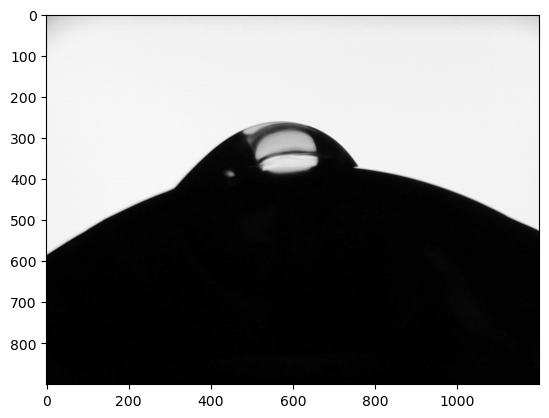

In [5]:
# TEST IMAGE CROP SIZE WITHOUT RUNNING ENTIRE CODE, MUST MANUALLY CHANGE (won't update from changes in def main())
def test_image_size():
    selection = ["all"]                       #CHANGE to pick which image to test, auto tests on first image in the list, see main() for naming convention
    
    droplet_pic, lens_pic = readImages(directory)
    experiment = "T&RH"                       #either "T&RH" or "B&R"
    droplet_pic, lens_pic = selectImages(selection, droplet_pic, lens_pic, experiment)
    print() #to make a new line
    
    ## Adjust Image Crop
    img_crop_values = [200, 1100, 200, 1400]  #CHANGE based on droplet image; img_crop_values: [y1, y2, x1, x2] --> img_crop = img[y1:y2,x1:x2]
    
    y1,y2,x1,x2 = test_droplet_img(directory, droplet_pic, img_crop_values)
test_image_size()

In [6]:
# EDIT INFO HERE, RUN IT AFTER RUNNING ALL OTHER FUNCTIONS
def main(directory, curve_eqns_filepath, data_sum_filepath):
    ## Pick which Images
    selection = ["all"]           #CHANGE based run, i.e. B&R: [1,2,3,...], ["run1_drop1","run2_drop1"] or ["all"]; T&RH: [0,1,2,3...] OR ["all"]

    droplet_pic, lens_pic = readImages(directory)
    experiment = "T&RH"           #CHANGE based on experiment, either "T&RH" or "B&R"

    droplet_pic, lens_pic = selectImages(selection, droplet_pic, lens_pic, experiment)

    print() #to make a new line
    
    # Adjust Image Crop
    img_crop_values = [200, 1100, 
                       200, 1400] #CHANGE from test_image_size()
    
    y1,y2,x1,x2 = test_droplet_img(directory, droplet_pic, img_crop_values)
    print() #to make a new line
    
    ## Adjust Contours
    min_len = 70                  #CHANGE: min length of droplet that code looks for
    alwaysEllipse = False         #CHANGE: set to True if only want to use Ellipse method
    alwaysTangent = False         #CHANGE: set to True if only want to use Tangent method
    
    autoLeft = True               #CHANGE: automatically cut leftCA if needed? if False, left_cut cannot be 0
    autoRight = True              #CHANGE: automatically cut rightCA if needed? if False, right_cut cannot be 0
    left_interfaceOffset = 30     #CHANGE: num of offset points from tangent point when automatically cutting left CA: 30 for highCA, 50 for lowCA
    right_interfaceOffset = 30    #CHANGE: num of offset points from tangent point when automatically cutting right CA: 31 for highCA, 51 for lowCA
    right_interfaceOffset += 1    #DO NOT CHANGE: +1 to account for index [-1] being last digit, where index [-2] is a cut of 1
    
    left_cut = 5                  #CHANGE: how much it cuts from left side of droplet (only works if autoLeft = False)
    right_cut = 0                 #CHANGE: how much it cuts from right side of droplet (only works if autoRight = False)
    right_cut += 1                #DO NOT CHANGE: +1 to account for index [-1] being last digit, where index [-2] is a cut of 1
    left = True                   #CHANGE: calculate left CA?
    right = True                  #CHANGE: calculate right CA?
    
    combined(droplet_pic, lens_pic, directory, y1,y2,x1,x2, min_len, autoLeft, autoRight, left_interfaceOffset, right_interfaceOffset, left_cut, right_cut, left, right, curve_eqns_filepath, data_sum_filepath, alwaysEllipse, alwaysTangent)

['/Image_0.jpg', '/Image_1.jpg', '/Image_2.jpg', '/Image_3.jpg', '/Image_4.jpg', '/Image_5.jpg', '/Image_6.jpg', '/Image_7.jpg', '/Image_8.jpg', '/Image_9.jpg']
['/pre_lens_0.jpg', '/pre_lens_1.jpg', '/pre_lens_2.jpg', '/pre_lens_3.jpg', '/pre_lens_4.jpg', '/pre_lens_5.jpg', '/pre_lens_6.jpg', '/pre_lens_7.jpg', '/pre_lens_8.jpg', '/pre_lens_9.jpg']

Test Crop: Image_0.jpg

1
/pre_lens_0.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 640.29066671 -897.38712961 1200.         1436.22955397]
2
/Image_0.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [561.25954904 505.06556393 205.81272072 129.53158304]
NRSME: 0.07436457711699342

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  506.5 vs tangent line y :  507.61111111111114
droplet contour x:  330.0 vs tangent line x :  [330.] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  555.0 vs tangent line y:  559.2857142857142
droplet contour x:  748.5 v

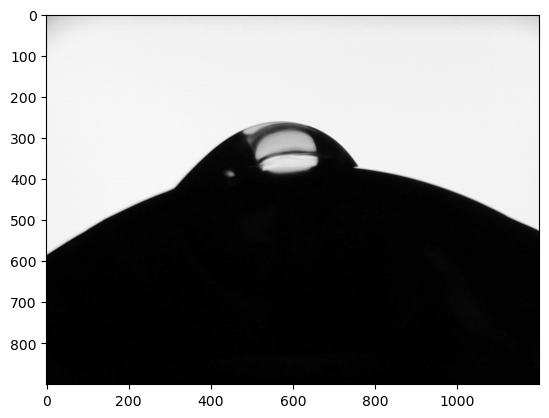

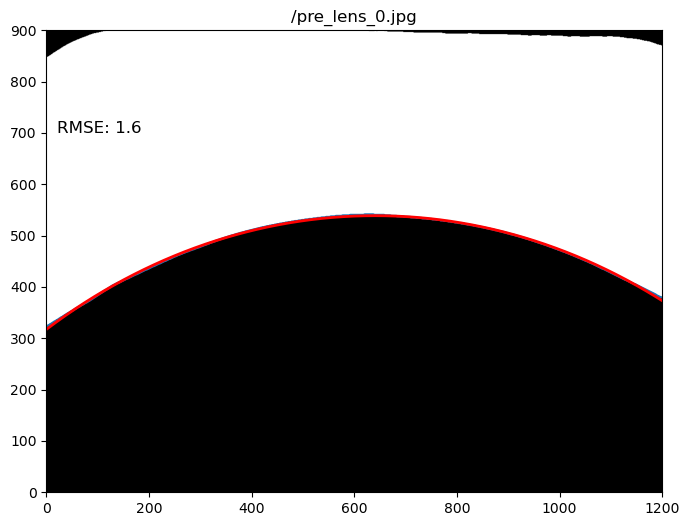

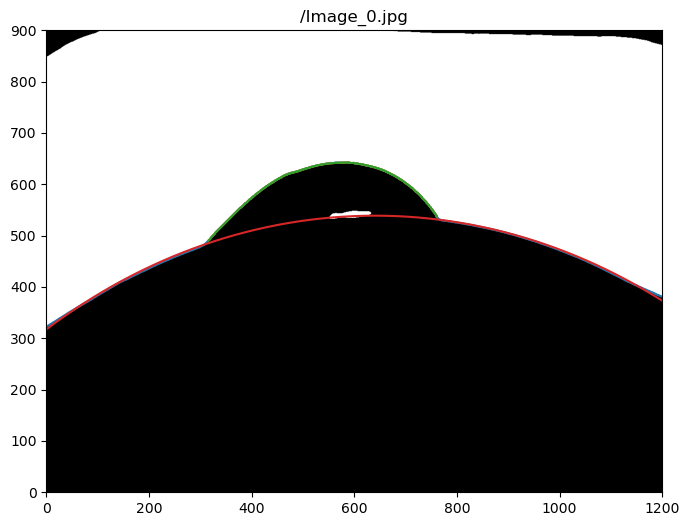

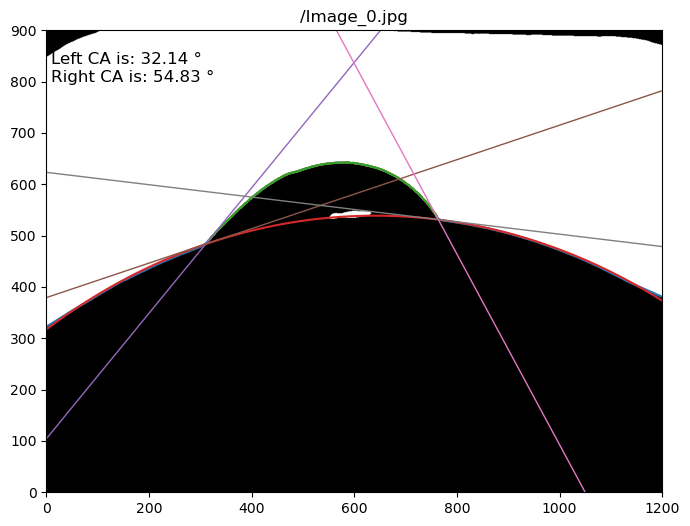

filename: 0_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/0_#0.png
3
/pre_lens_1.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 637.92542295 -900.         1192.3955048  1440.49135913]
4
/Image_1.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [572.55701262 524.11826737 157.17709789 151.80970957]
NRSME: 0.009957704690412527

RUNNING TANGENT METHOD:
LEFT SIDE:
droplet contour y:  573.0 vs tangent line y :  585.0
droplet contour x:  422.5 vs tangent line x :  [422.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  566.0 vs tangent line y:  566.0
droplet contour x:  723.5 vs tangent line x :  [723.5] 

left_cut = 19
right_cut = 0


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


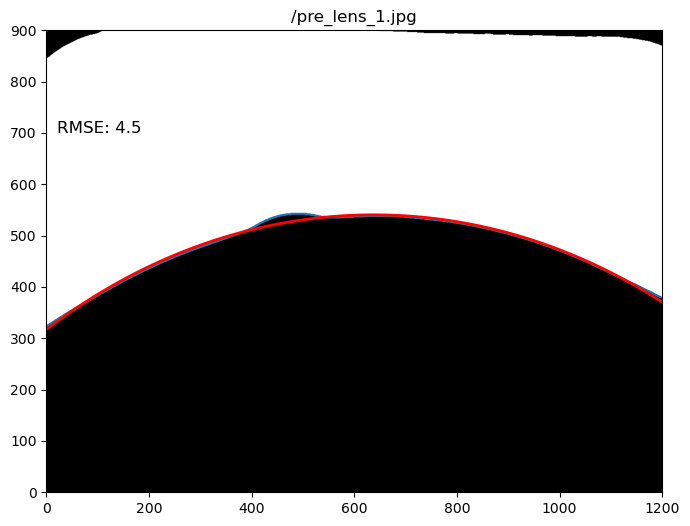

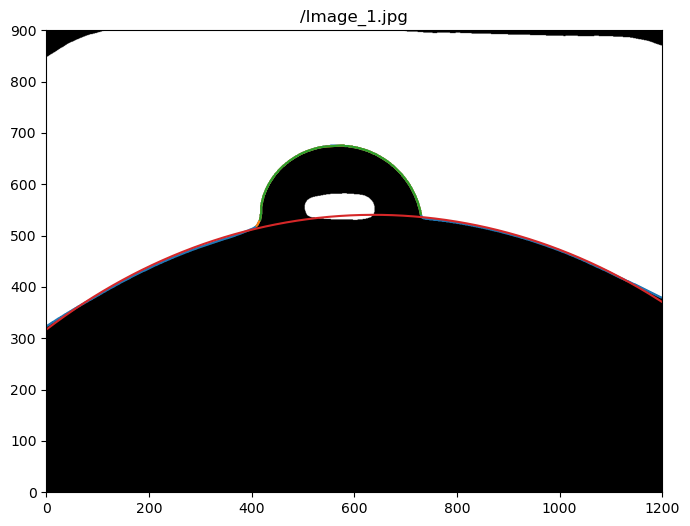

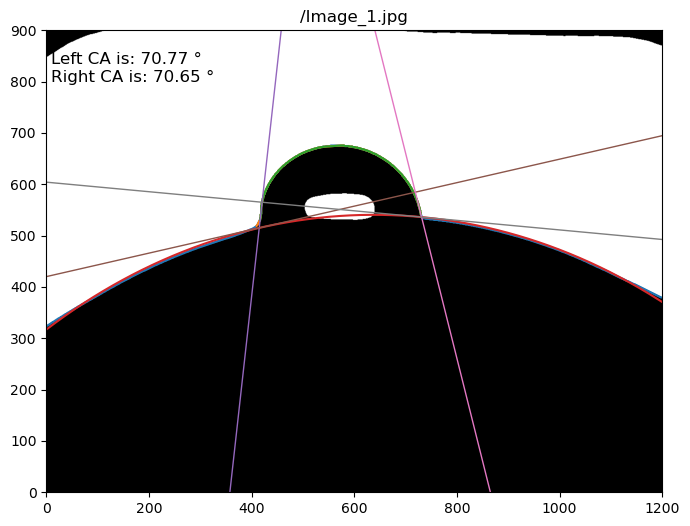

filename: 1_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/1_#0.png
5
/pre_lens_2.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.30085669 -895.55605967 1200.         1434.02074431]
6
/Image_2.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [578.11014998 549.8029105  144.61014098 130.0469461 ]
NRSME: 0.013938351782251977

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  551.0 vs tangent line y :  541.0
droplet contour x:  431.5 vs tangent line x :  [431.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  566.5 vs tangent line y:  571.5
droplet contour x:  722.0 vs tangent line x :  [722.] 

left_cut = 0
right_cut = 0


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


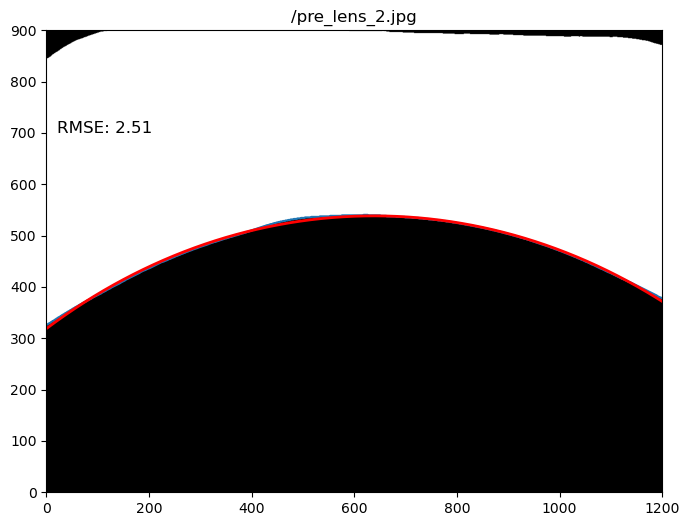

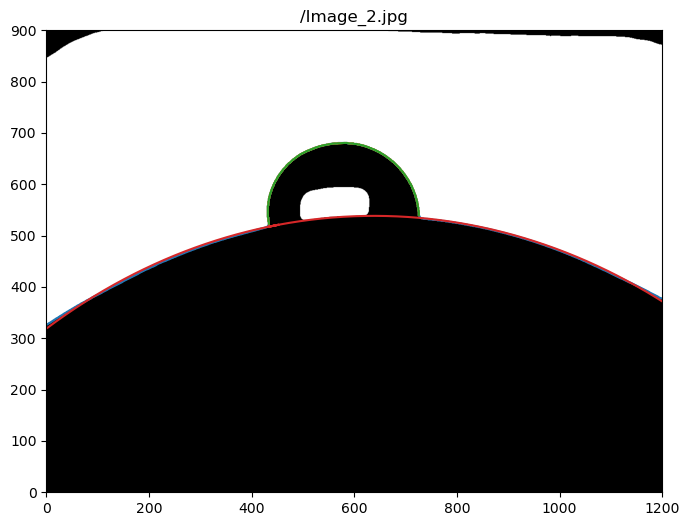

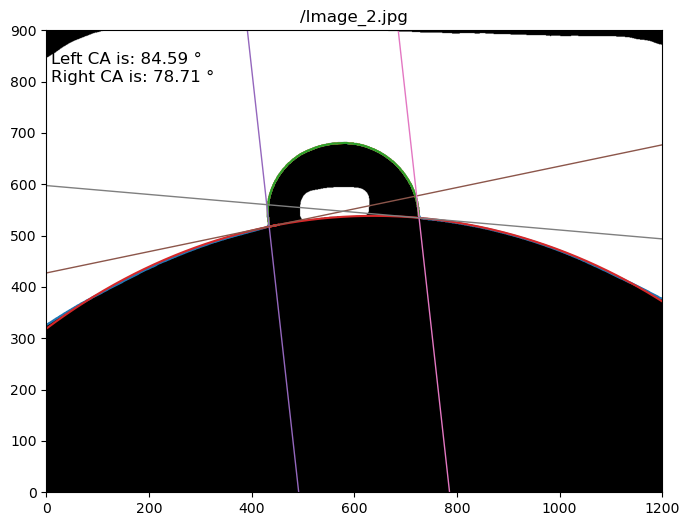

filename: 2_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/2_#0.png
7
/pre_lens_3.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.03505047 -888.08683121 1200.         1425.120915  ]
8
/Image_3.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [569.48069789 529.10728149 152.04887272 150.13801187]
NRSME: 0.0030532770185519465


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


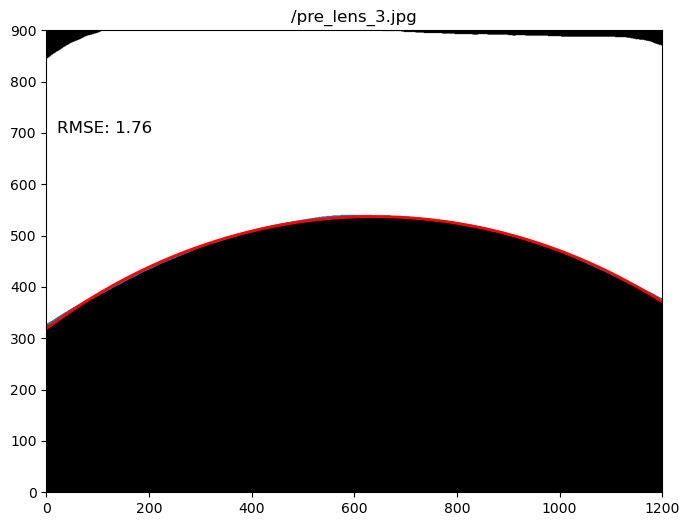

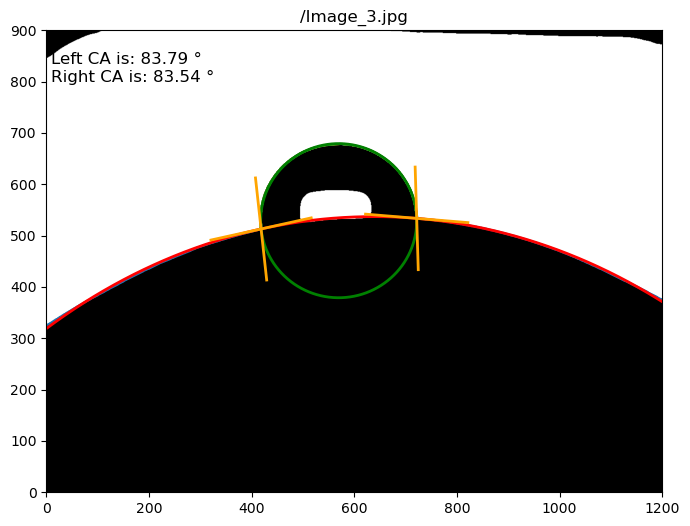

filename: 3_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/3_#0.png
9
/pre_lens_4.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.33353587 -885.37370092 1200.         1421.65457232]
10
/Image_4.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [601.83507615 534.91306504 151.0995014  144.2413059 ]
NRSME: 0.0022408902072166455


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])


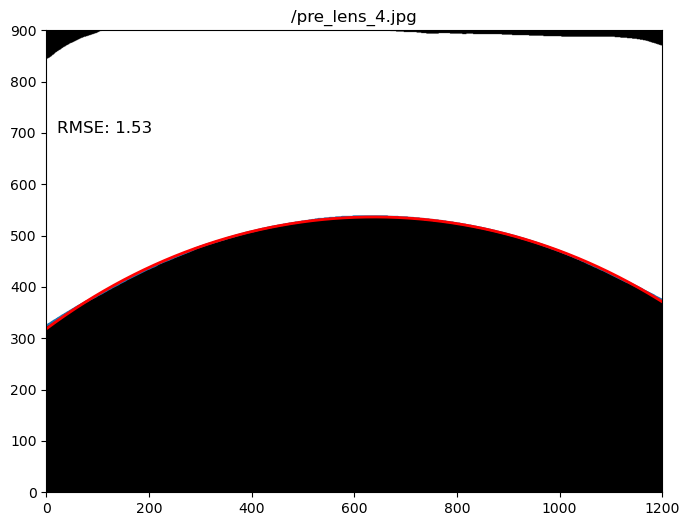

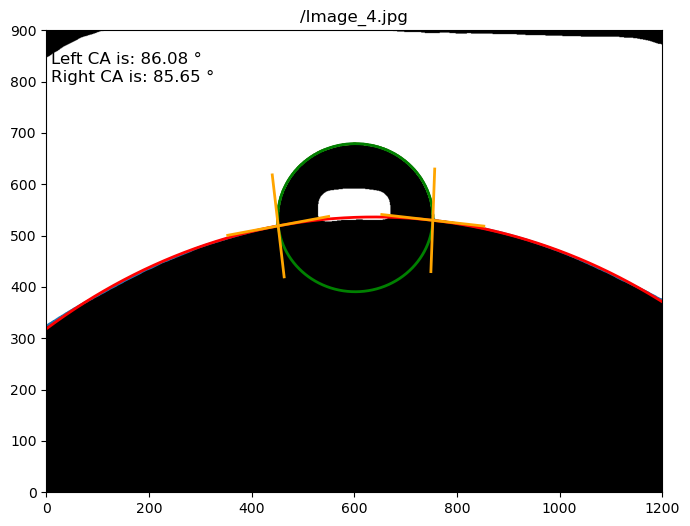

filename: 4_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/4_#0.png
11
/pre_lens_5.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.70763581 -888.05598437 1200.         1423.94414227]
12
/Image_5.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [558.30973162 551.34245072 141.8097175  136.69133328]
NRSME: 0.016092830962945278

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  543.5 vs tangent line y :  536.8333333333335
droplet contour x:  414.0 vs tangent line x :  [414.] 

RIGHT SIDE:
droplet contour y:  567.0 vs tangent line y:  nan
droplet contour x:  699.5 vs tangent line x :  [699.] 

left_cut = 0
right_cut = 1


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:347: RuntimeWarning: divide by zero encountered in scalar divide
  right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in add
  return (m * x) + b
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in mul

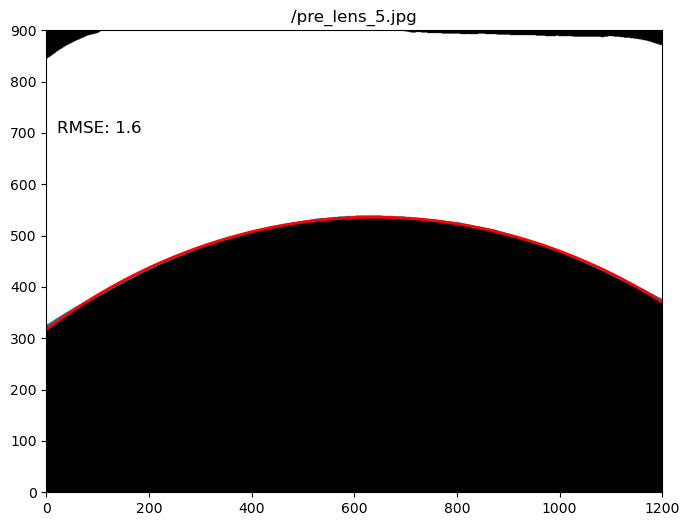

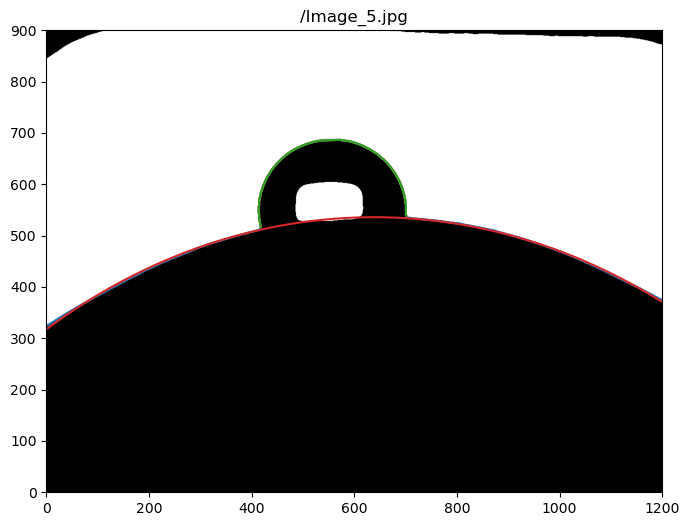

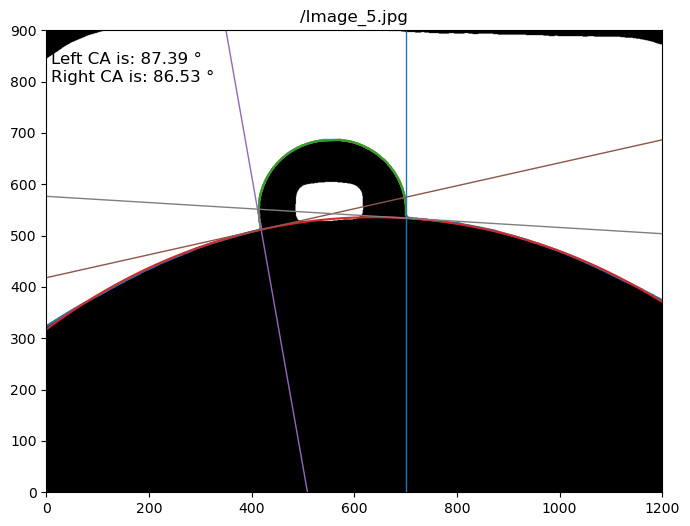

filename: 5_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/5_#0.png
13
/pre_lens_6.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.70347451 -888.89040879 1200.         1424.47396113]
14
/Image_6.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [606.30866014 553.49958113 143.80865724 138.16625451]
NRSME: 0.0113677212974469

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  554.0 vs tangent line y :  544.0
droplet contour x:  460.5 vs tangent line x :  [460.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  564.5 vs tangent line y:  nan
droplet contour x:  750.0 vs tangent line x :  [750.] 

left_cut = 0
right_cut = 0


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:347: RuntimeWarning: divide by zero encountered in scalar divide
  right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in add
  return (m * x) + b
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in mul

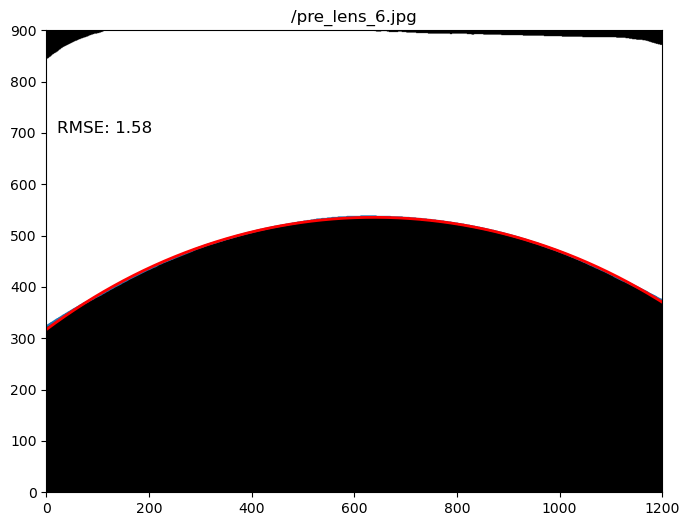

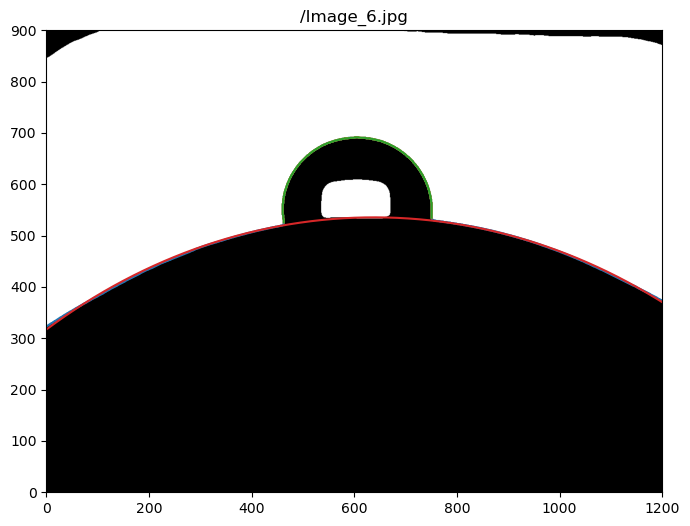

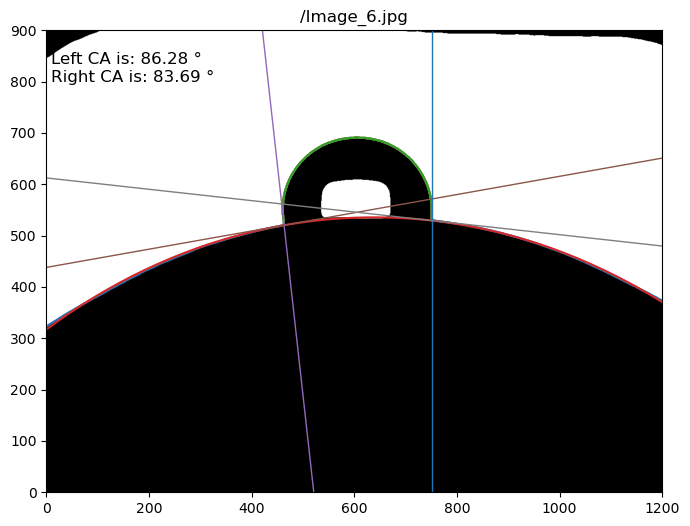

filename: 6_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/6_#0.png
15
/pre_lens_7.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.73317085 -890.19761265 1200.         1425.31339581]
16
/Image_7.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [565.47108428 549.56154086 141.97107272 135.93663369]
NRSME: 0.013119504530543155

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  545.0 vs tangent line y :  535.0
droplet contour x:  421.5 vs tangent line x :  [421.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  566.0 vs tangent line y:  nan
droplet contour x:  706.5 vs tangent line x :  [706.5] 

left_cut = 0
right_cut = 0


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:347: RuntimeWarning: divide by zero encountered in scalar divide
  right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in add
  return (m * x) + b
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in mul

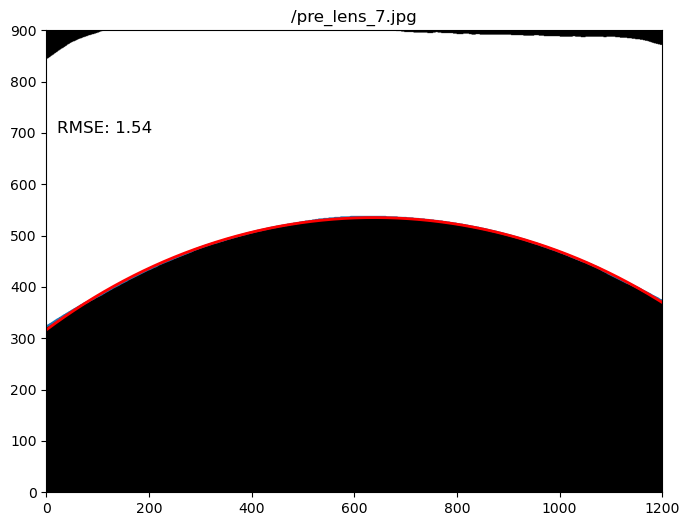

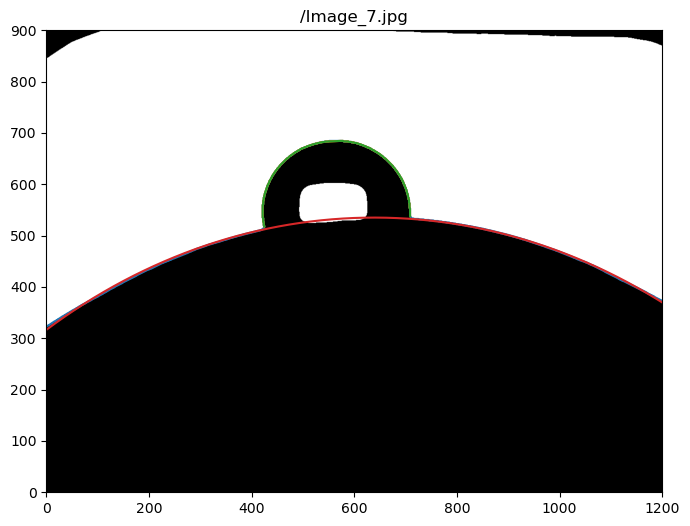

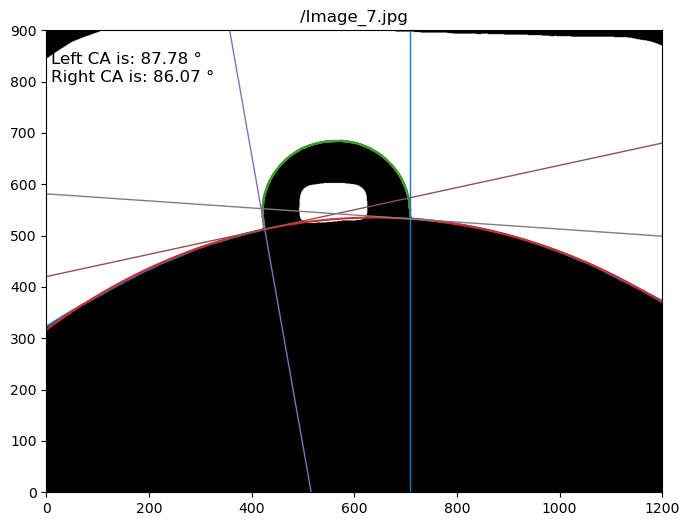

filename: 7_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/7_#0.png
17
/pre_lens_8.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.55935686 -890.73552364 1200.         1425.57016118]
18
/Image_8.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [583.39099337 551.16907599 143.72413773 139.47366855]
NRSME: 0.012366961652294336

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  548.0 vs tangent line y :  548.0
droplet contour x:  437.5 vs tangent line x :  [437.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  565.0 vs tangent line y:  nan
droplet contour x:  726.5 vs tangent line x :  [726.5] 

left_cut = 0
right_cut = 0


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:347: RuntimeWarning: divide by zero encountered in scalar divide
  right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in add
  return (m * x) + b
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in mul

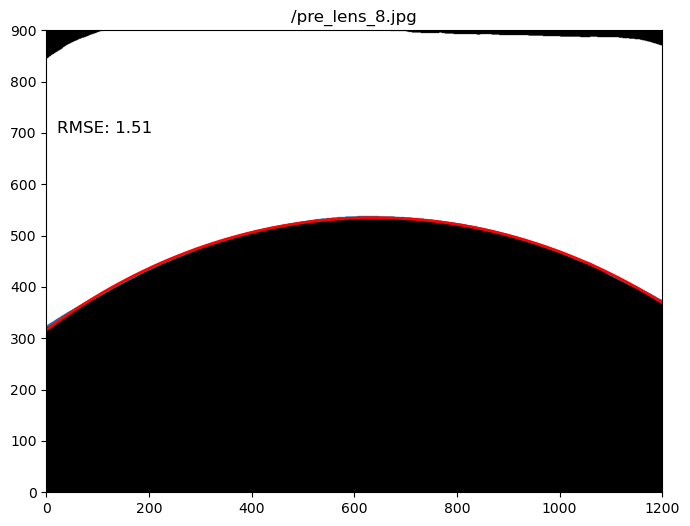

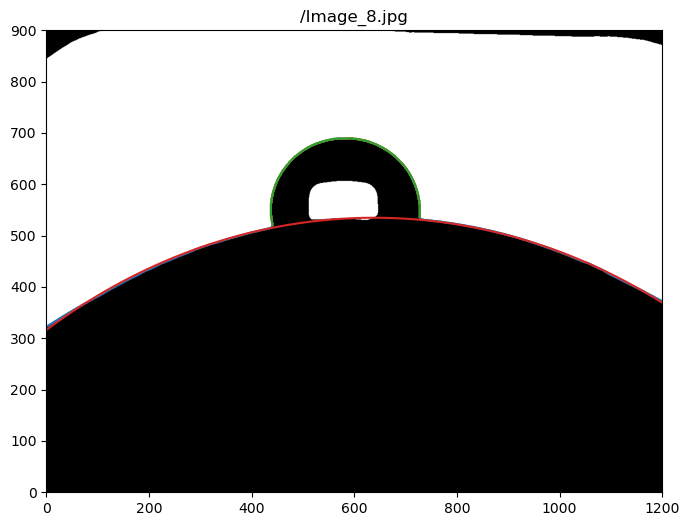

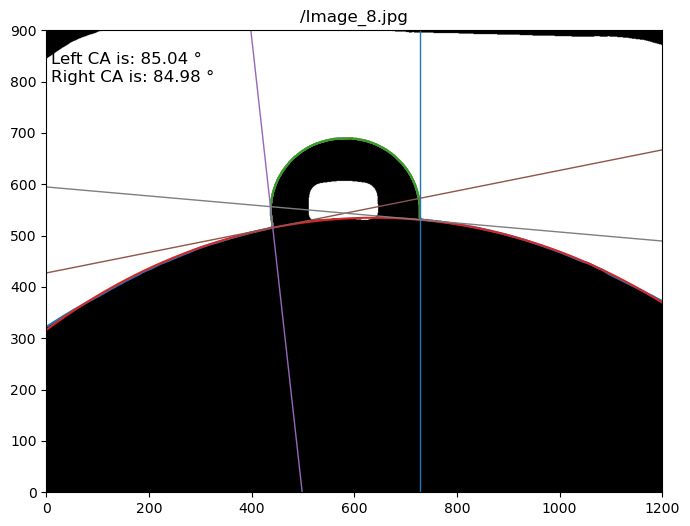

filename: 8_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/8_#0.png
19
/pre_lens_9.jpg
Parameters of lens curve equation - x_offset, y_offset, a, b: [ 638.47200035 -893.31025926 1200.         1428.00102571]
20
/Image_9.jpg
RUNNING ELLIPSE METHOD:
Parameters of droplet curve equation - x_offset, y_offset, a, b: [577.92102666 549.23142287 144.42102642 137.50290946]
NRSME: 0.013442251618774331

RUNNING TANGENT METHOD:
NO LEFT CUT NEEDED
LEFT SIDE:
droplet contour y:  547.0 vs tangent line y :  537.0
droplet contour x:  431.5 vs tangent line x :  [431.5] 

NO RIGHT CUT NEEDED
RIGHT SIDE:
droplet contour y:  565.0 vs tangent line y:  nan
droplet contour x:  721.5 vs tangent line x :  [721.5] 

left_cut = 0
right_cut = 0


/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:187: RuntimeWarning: divide by zero encountered in scalar divide
  main_contour_slope = (main_contour_y[j+20] - main_contour_y[j+10])/(main_contour_x[j+20] - main_contour_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:188: RuntimeWarning: invalid value encountered in scalar divide
  lens_curve_slope = (lens_curve_y[j+20] - lens_curve_y[j+10])/(lens_curve_x[j+20] - lens_curve_x[j+10])
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:347: RuntimeWarning: divide by zero encountered in scalar divide
  right_drop_slope = right_drop_vector[1]/right_drop_vector[0]
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in add
  return (m * x) + b
/var/folders/yd/_xt6vzvs0w56gst9v2h7rl8r0000gn/T/ipykernel_47814/1654465165.py:135: RuntimeWarning: invalid value encountered in mul

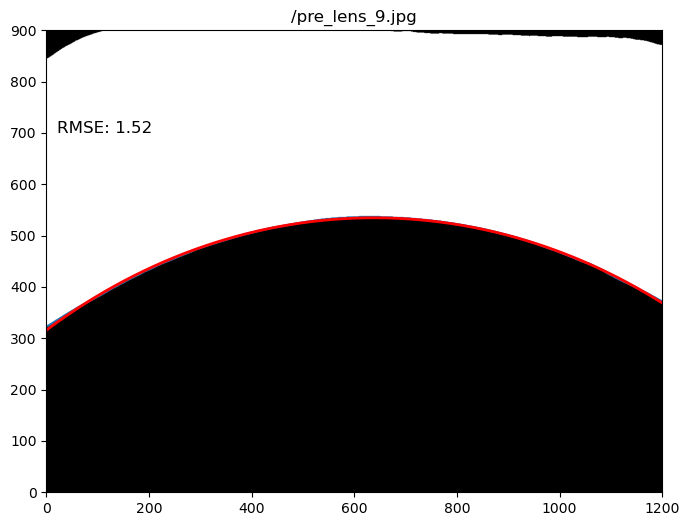

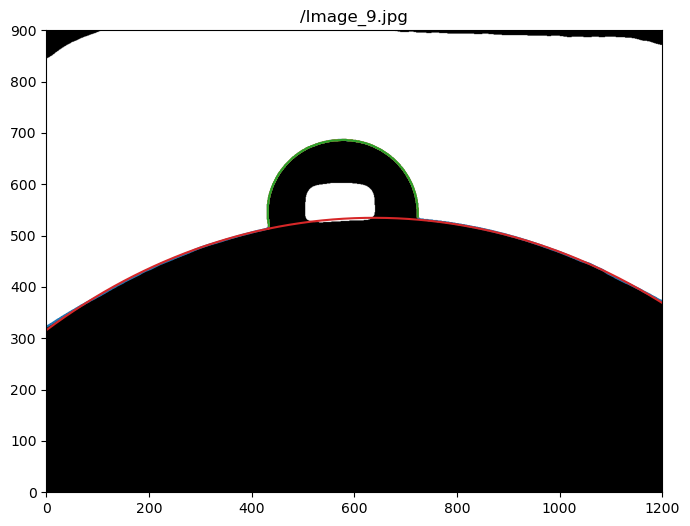

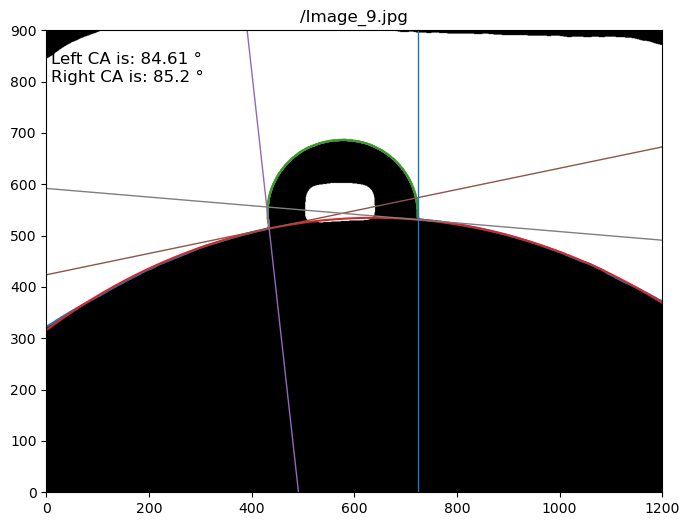

filename: 9_#0.png
full_path: ./Image Processing/20260812/20260812-senofilcon AOH-4p1m-RV-37 (1)/Processed_Data/9_#0.png


In [7]:
main(directory, curve_eqns_filepath, data_sum_filepath)